# Лабораторна робота №1
## Варіант 012 — смарт-лічильники електроенергії
У варіанті потрібні 200 лічильників і всі 15-хвилинні записи березня. Це має пріоритет над загальним обмеженням 1000–3000 рядків. Аналогічно ціль повторів становить 1,5–2%. Фіксований seed робить усі випадкові дії відтворюваними.



## 0. Налаштування
Виконувати з каталогу `project`. Час зберігається як реальний момент POSIXct; для тарифу використовується місцевий час Києва.



In [1]:
RANDOM_SEED <- 12012
set.seed(RANDOM_SEED)
if (.Platform$OS.type == "windows") {
  locale_result <- Sys.setlocale("LC_CTYPE", "Ukrainian_Ukraine.utf8")
  stopifnot(!is.na(locale_result), nzchar(locale_result))
}
suppressPackageStartupMessages({
  library(data.table)
  library(lubridate)
  library(ggplot2)
})
if (!dir.exists("data") && dir.exists("../data")) setwd("..")
N_METERS <- 200L; N_SITES <- 50L
CITIES <- c("Kyiv", "Lviv", "Odesa")
LOCAL_TZ <- "Europe/Kyiv"; COUNTER_MAX <- 10000
for (path in c("data/raw", "data/clean", "outputs/figures")) dir.create(path, recursive=TRUE, showWarnings=FALSE)
time_grid <- seq(as.POSIXct("2024-03-01 00:00:00", tz=LOCAL_TZ),
                 as.POSIXct("2024-03-31 23:45:00", tz=LOCAL_TZ), by="15 min")
stopifnot(length(time_grid) == 2972L)
cat("Інтервалів у часовій сітці:", length(time_grid), "\n")



Інтервалів у часовій сітці: 2972 


## 1. Генерація даних
31 березня після 02:45 одразу настає 04:00: година 03:00–03:45 не існує. Отже, березень має 2972 інтервали. Для накопичувальних сегментів обрано лічильники без PV, щоб не змішувати експорт і лічильник імпорту.



In [2]:
sites <- data.table(site_id=sprintf("S%03d", seq_len(N_SITES)),
                    city=rep(CITIES, length.out=N_SITES),
                    site_factor=runif(N_SITES, .94, 1.06),
                    price_t1=round(runif(N_SITES, 3.8, 5.2), 3),
                    night_factor=runif(N_SITES, .5, .7))
tariff_ref <- rbind(
  sites[, .(site_id, city, tariff="T1", price_uah_kwh=price_t1)],
  sites[, .(site_id, city, tariff="T2", price_uah_kwh=round(price_t1*night_factor, 3))])
setorder(tariff_ref, site_id, tariff)
fwrite(tariff_ref, "data/tariff_reference.csv")
meters <- data.table(meter_id=sprintf("M%04d", seq_len(N_METERS)),
                     site_id=rep(sites$site_id, each=4),
                     pv_flag=as.integer(seq_len(N_METERS) %in% sample.int(N_METERS, 30)),
                     base_load=runif(N_METERS, .34, .65),
                     meter_profile_factor=runif(N_METERS, .80, 1.20))
meters <- merge(meters, sites[, .(site_id, city, site_factor)], by="site_id", sort=FALSE)
grid <- CJ(meter_id=meters$meter_id, timestamp=time_grid)
setkey(meters, meter_id)
df <- meters[grid, on="meter_id"]
setorder(df, meter_id, timestamp)
local_hour <- hour(df$timestamp) + minute(df$timestamp)/60
weekday <- wday(df$timestamp, week_start=1)
daily_factor <- fifelse(local_hour < 6, .58,
                 fifelse(local_hour < 9, 1.10,
                 fifelse(local_hour < 17, .95,
                 fifelse(local_hour < 22, 1.35, .80))))
weekend_factor <- fifelse(weekday >= 6, fifelse(local_hour >= 9 & local_hour < 22, 1.09, .95), 1)
city_factor <- c(Kyiv=1.04, Lviv=.99, Odesa=.96)[df$city]
solar <- pmax(0, sin(pi*(local_hour-8)/10))
n <- nrow(df)
df[, kwh := round(base_load*meter_profile_factor*site_factor*city_factor*daily_factor*weekend_factor*
                    pmax(.35, rnorm(n, 1, .13)) - pv_flag*solar*runif(n, .4, 1.15), 4)]
df[, voltage_v := round(rnorm(n, 230 + (site_factor-1)*20, 4.5), 3)]
df[, power_factor := round(pmin(.99, pmax(.85, rnorm(n, .93, .025))), 4)]
df[, current_a := round(abs(kwh)*4000/(voltage_v*power_factor), 4)]
df[, kvarh := round(abs(kwh)*tan(acos(power_factor)), 4)]
df[, quality_flag := sample(c("OK", "EST", "OUTAGE"), n, TRUE, c(.955,.03,.015))]
df[, note := fifelse(kwh < 0 & pv_flag == 1, "PV export",
             fifelse(quality_flag == "EST", "estimated reading",
             fifelse(quality_flag == "OUTAGE", "outage", "")))]
df[, tariff := fifelse(hour(timestamp) >= 23 | hour(timestamp) < 7, "T2", "T1")]
df <- merge(df, tariff_ref[, .(site_id, tariff, price_uah_kwh)], by=c("site_id","tariff"), sort=FALSE)
setorder(df, meter_id, timestamp)
df[, reading_type := "interval"]



        site_id tariff meter_id pv_flag base_load meter_profile_factor   city
         <char> <char>   <char>   <int>     <num>                <num> <char>
     1:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     2:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     3:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     4:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     5:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
    ---                                                                      
594396:    S050     T1    M0200       0 0.6391235            1.0916491   Lviv
594397:    S050     T2    M0200       0 0.6391235            1.0916491   Lviv
594398:    S050     T2    M0200       0 0.6391235            1.0916491   Lviv
594399:    S050     T2    M0200       0 0.6391235            1.0916491   Lviv
594400:    S050     T2    M0200       0 0.6391235            1.0

### 1.1 Накопичувальні показники, rollover та помилки
У кожного з 24 вибраних лічильників є шість коротких накопичувальних фрагментів. Один із 144 фрагментів переходить через межу 10000 kWh.



In [3]:
cum_meters <- sample(meters[pv_flag == 0, meter_id], 24)
cum_segments_per_meter <- 6L
for (j in seq_along(cum_meters)) {
  meter_rows <- which(df$meter_id == cum_meters[j])
  for (segment in seq_len(cum_segments_per_meter)) {
    start_slot <- 180L + (segment-1L)*430L + sample(0:45,1)
    ix <- meter_rows[start_slot:(start_slot+29L)]
    initial <- if (j == 1L && segment == 1L) 9998 else runif(1, 1000, 8000)
    df[ix, `:=`(reading_type="cumulative", kwh=round((initial+cumsum(pmax(kwh,0))) %% COUNTER_MAX,4))]
  }
}
cum_series_count <- length(cum_meters)*cum_segments_per_meter
rollover_created <- df[reading_type=="cumulative",
  sum(kwh < shift(kwh) & shift(kwh)>9900,na.rm=TRUE),by=meter_id][,sum(V1)]
# MAR: частіше вночі, за T2 і під час відключення.
miss_kwh_p <- .078 + .035*(df$tariff == "T2") + .12*(df$quality_flag == "OUTAGE")
miss_volt_p <- .112 + .10*(df$quality_flag == "OUTAGE")
df[runif(n) < miss_kwh_p, kwh := NA_real_]
df[runif(n) < miss_volt_p, voltage_v := NA_real_]
interval_ix <- which(df$reading_type == "interval" & !is.na(df$kwh))
extreme_ix <- sample(interval_ix, round(.007*n))
df[extreme_ix, kwh := sample(c(18,22,30,40), .N, TRUE)]
bad_neg_ix <- sample(setdiff(which(df$reading_type == "interval" & df$pv_flag == 0 & !is.na(df$kwh)), extreme_ix), 850)
df[bad_neg_ix, kwh := -runif(.N, .1, 13)]
volt_ix <- sample(which(!is.na(df$voltage_v)), round(.01*n))
df[volt_ix, voltage_v := sample(c(110,140,285,310), .N, TRUE)]
pf_ix <- sample.int(n, round(.005*n))
df[pf_ix, power_factor := sample(c(-.2,1.05,1.25), .N, TRUE)]
# Рідкісна неможлива експортна величина.
pv_bad_ix <- sample(which(df$pv_flag == 1 & !is.na(df$kwh) & df$kwh < 0), 20)
df[pv_bad_ix, kwh := -runif(.N, 11, 18)]



Index: <reading_type>
        site_id tariff meter_id pv_flag base_load meter_profile_factor   city
         <char> <char>   <char>   <int>     <num>                <num> <char>
     1:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     2:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     3:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     4:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
     5:    S001     T2    M0001       0 0.4067628            0.9318317   Kyiv
    ---                                                                      
594396:    S050     T1    M0200       0 0.6391235            1.0916491   Lviv
594397:    S050     T2    M0200       0 0.6391235            1.0916491   Lviv
594398:    S050     T2    M0200       0 0.6391235            1.0916491   Lviv
594399:    S050     T2    M0200       0 0.6391235            1.0916491   Lviv
594400:    S050     T2    M0200       0 0.

In [4]:
# Структурні прогалини фізично видаляють рядки, включно з довгими блоками.
removed_ix <- integer()
for (meter in sample(meters$meter_id, 35)) {
  start_slot <- sample(100:2800, 1)
  slots <- time_grid[start_slot:(start_slot+sample(4:12,1)-1L)]
  removed_ix <- c(removed_ix, which(df$meter_id == meter & df$timestamp %in% slots))
}
structural_removed <- length(unique(removed_ix))
df <- df[-unique(removed_ix)]
setorder(df, meter_id, timestamp)
df[, record_id := sprintf("R%07d", .I)]
df[, tz := fifelse(runif(.N) < .20, "UTC", LOCAL_TZ)]
df[, timestamp_text := fifelse(tz == "UTC", format(timestamp, "%Y-%m-%d %H:%M:%S", tz="UTC"),
                              format(timestamp, "%Y-%m-%d %H:%M:%S", tz=LOCAL_TZ))]
non_iso <- runif(nrow(df)) < .10
df[non_iso, timestamp_text := fifelse(tz == "UTC", format(timestamp, "%d.%m.%Y %H:%M", tz="UTC"),
                                      format(timestamp, "%d.%m.%Y %H:%M", tz=LOCAL_TZ))]
# Невеликий DST glitch: локальний слот зсунуто на 15 хвилин у десяти лічильників.
dst_meters <- sample(meters$meter_id, 10)
dst_ix <- which(df$meter_id %in% dst_meters & df$timestamp == as.POSIXct("2024-03-31 04:00:00",tz=LOCAL_TZ))
df[dst_ix, `:=`(tz=LOCAL_TZ, timestamp_text="2024-03-31 04:15:00")]
# Неправильний тариф за UTC-годиною.
utc_ix <- which(df$tz == "UTC")
df[utc_ix, tariff := fifelse(hour(with_tz(timestamp,"UTC")) >= 23 |
                              hour(with_tz(timestamp,"UTC")) < 7, "T2", "T1")]
df[, timestamp := NULL]
setnames(df, "timestamp_text", "timestamp")
# Систематичні варіанти текстових категорій і невидимі символи у примітках.
city_ix <- sample.int(nrow(df), round(.025*nrow(df)))
df[city_ix, city := fifelse(city=="Kyiv", sample(c("kyiv","KYIV"," Kyiv","Kyiv "),.N,TRUE),
                    fifelse(city=="Lviv",sample(c("lviv","LVIV","Lviv "),.N,TRUE),
                            sample(c("odesa","ODESA"," Odesa"),.N,TRUE)))]
quality_ix <- sample.int(nrow(df), round(.02*nrow(df)))
df[quality_ix, quality_flag := fifelse(quality_flag == "OK", " ok ", fifelse(quality_flag == "EST", " est ", " Outage "))]
note_ix <- sample.int(nrow(df), round(.01*nrow(df)))
df[note_ix, note := sample(c(" PV  export ","\u200bOUTAGE","meter   estimated","solar\tgeneration","power\noutage","PV\u00a0export"), .N, TRUE)]
# Десяткові коми і пробіли тисяч у приблизно 8% значень кожного поля.
for (field in c("kwh","kvarh","voltage_v","current_a","price_uah_kwh")) {
  value <- as.character(df[[field]])
  ix <- sample(which(!is.na(value)), round(.08*sum(!is.na(value))))
  value[ix] <- gsub("\\.", ",", value[ix])
  spaced <- sample(ix, round(.15*length(ix)))
  value[spaced] <- paste0(" ", value[spaced], "\u00a0")
  set(df, j=field, value=value)
}
# Дублі спершу точні, потім часткові з новим record_id.
duplicate_n <- round(.018*nrow(df))
source_ix <- sample.int(nrow(df), duplicate_n)
full_n <- floor(duplicate_n/2)
full <- copy(df[source_ix[seq_len(full_n)]])
partial <- copy(df[source_ix[(full_n+1):duplicate_n]])
partial[, record_id := sprintf("D%07d", seq_len(.N))]
partial[, `:=`(quality_flag=" ok ", note=paste0(" ", note, "  "))]
raw_generated <- rbindlist(list(df, full, partial), use.names=TRUE)
raw_generated[, c("base_load","meter_profile_factor","site_factor") := NULL]
setcolorder(raw_generated, c("record_id","meter_id","site_id","city","timestamp","tz","reading_type",
                             "kwh","kvarh","voltage_v","current_a","power_factor","tariff",
                             "price_uah_kwh","quality_flag","note","pv_flag"))
fwrite(raw_generated, "data/raw/generated_dirty.csv", na="")
rm(df, full, partial, raw_generated, grid); gc(FALSE)



          used (Mb) gc trigger  (Mb) max used  (Mb)
Ncells 1034458 55.3    3188948 170.4  1932507 103.3
Vcells 8873669 67.8   33908020 258.7 42280613 322.6


## 2. Статистика до очистки
Дані повторно читаються з CSV. Числові поля навмисно прочитуються як текст, щоб показати очищення десяткових ком і пробілів.



In [5]:
raw <- fread("data/raw/generated_dirty.csv", colClasses=list(character=c("kwh","kvarh","voltage_v","current_a","price_uah_kwh")), na.strings=c("","NA"))
raw_input_columns <- names(raw)
parse_dirty_number <- function(x) {
  x <- gsub("[\u00a0\u202f[:space:]]", "", as.character(x), perl=TRUE)
  suppressWarnings(as.numeric(gsub(",", ".", x, fixed=TRUE)))
}
normalize_city <- function(x) {
  y <- tolower(trimws(x)); ifelse(y=="kyiv","Kyiv",ifelse(y=="lviv","Lviv",ifelse(y=="odesa","Odesa",NA_character_)))
}
normalize_quality_flag <- function(x) toupper(trimws(x))
clean_note <- function(x) trimws(gsub("[[:space:]\u00a0]+", " ", gsub("\u200b", "", x, perl=TRUE), perl=TRUE))
parse_mixed_timestamp <- function(timestamp, tz_value) {
  x <- gsub("T"," ",timestamp,fixed=TRUE)
  out <- as.POSIXct(rep(NA_real_, length(x)), origin="1970-01-01", tz=LOCAL_TZ)
  for (source_tz in c("UTC",LOCAL_TZ)) for (dmy in c(FALSE,TRUE)) {
    ix <- which(tz_value == source_tz & grepl("^[0-9]{2}\\.", x) == dmy)
    if (!length(ix)) next
    fmt <- if (dmy) "%d.%m.%Y %H:%M" else "%Y-%m-%d %H:%M:%S"
    naive <- as.POSIXct(x[ix], format=fmt, tz="UTC")
    # force_tz тлумачить написані цифри у вихідному поясі; with_tz лише змінює відображення моменту.
    out[ix] <- as.numeric(with_tz(force_tz(naive, source_tz), LOCAL_TZ))
  }
  out
}
raw[, `:=`(kwh_num=parse_dirty_number(kwh), voltage_num=parse_dirty_number(voltage_v),
          price_num=parse_dirty_number(price_uah_kwh), city_norm=normalize_city(city))]
raw[, local_timestamp := parse_mixed_timestamp(timestamp,tz)]
raw[, local_tariff := fifelse(hour(local_timestamp)>=23 | hour(local_timestamp)<7,"T2","T1")]
raw[, full_duplicate := duplicated(raw, by=names(raw)[!names(raw) %in% c("kwh_num","voltage_num","price_num","city_norm","local_timestamp","local_tariff")])]
logical_duplicates <- nrow(raw) - uniqueN(raw, by=c("meter_id","local_timestamp"))
mixed_meters <- raw[, uniqueN(reading_type), by=meter_id][V1 > 1, .N]
generation_quality <- data.table(
  metric=c("лічильники","об'єкти","рядки","UTC, %","DD.MM, %","kWh NA, %","напруга NA, %","повтори, %","точні повтори","часткові повтори","змішані meter, %","PV meter, %","екстремальна напруга, %","PF поза [0,1], %","kWh >15, %","rollover","rollover серій, %","видалені структурні рядки"),
  actual=c(uniqueN(raw$meter_id),uniqueN(raw$site_id),nrow(raw),100*mean(raw$tz=="UTC"),
           100*mean(grepl("^[0-9]{2}\\.",raw$timestamp)),100*mean(is.na(raw$kwh_num)),
           100*mean(is.na(raw$voltage_num)),100*logical_duplicates/nrow(raw),
           sum(raw$full_duplicate),logical_duplicates-sum(raw$full_duplicate),
           100*mixed_meters/N_METERS,100*meters[,mean(pv_flag)],
           100*mean(raw$voltage_num<150 | raw$voltage_num>270,na.rm=TRUE),
           100*mean(raw$power_factor<0 | raw$power_factor>1,na.rm=TRUE),
           100*mean(raw$kwh_num>15 & raw$reading_type=="interval",na.rm=TRUE),
           rollover_created,100*rollover_created/cum_series_count,structural_removed),
  required=c("200","50",">590000","18–22%","8–12%","8–12%","10–14%","1.5–2%",">0",">0","12%","10–20%","~1%","~0.5%","~0.7%",">0","0.5–1%",">0"))
generation_ok <- c(generation_quality$actual[1]==200, generation_quality$actual[2]==50,
  generation_quality$actual[3]>590000, generation_quality$actual[4] %between% c(18,22),
  generation_quality$actual[5] %between% c(8,12), generation_quality$actual[6] %between% c(8,12),
  generation_quality$actual[7] %between% c(10,14), generation_quality$actual[8] %between% c(1.5,2),
  generation_quality$actual[9]>0, generation_quality$actual[10]>0,
  generation_quality$actual[11] %between% c(11,13), generation_quality$actual[12] %between% c(10,20),
  generation_quality$actual[13] %between% c(.7,1.5), generation_quality$actual[14] %between% c(.3,.7),
  generation_quality$actual[15] %between% c(.6,.9), generation_quality$actual[16]>0,
  generation_quality$actual[17] %between% c(.5,1),generation_quality$actual[18]>0)
generation_quality[, status := fifelse(generation_ok,"PASS","FAIL")]
print(generation_quality)
fwrite(generation_quality,"outputs/generation_quality.csv")
stopifnot(all(generation_ok))
cat("Типи raw:\n"); print(sapply(raw[, .(kwh,voltage_v,timestamp,reading_type)],class))
raw_numeric_summary <- raw[, .(n=.N, kwh_mean=mean(kwh_num,na.rm=TRUE), kwh_median=median(kwh_num,na.rm=TRUE),
                               kwh_p95=as.numeric(quantile(kwh_num,.95,na.rm=TRUE)),
                               voltage_mean=mean(voltage_num,na.rm=TRUE), missing_kwh=mean(is.na(kwh_num))), by=city_norm]
print(raw_numeric_summary)
cat("Raw quality:\n"); print(raw[, .N, by=quality_flag][order(-N)][1:8])
cat("Raw reading type:\n"); print(raw[, .N, by=reading_type])
cat("Raw mismatch тарифу:", sum(raw$tariff != raw$local_tariff,na.rm=TRUE), "\n")
cat("Raw DST 31.03, 03:xx:", sum(format(raw$local_timestamp,"%Y-%m-%d %H",tz=LOCAL_TZ)=="2024-03-31 03",na.rm=TRUE),"\n")



                       metric       actual required status
                       <char>        <num>   <char> <char>
 1:                лічильники 2.000000e+02      200   PASS
 2:                   об'єкти 5.000000e+01       50   PASS
 3:                     рядки 6.048350e+05  >590000   PASS
 4:                    UTC, % 2.002067e+01   18–22%   PASS
 5:                  DD.MM, % 9.969826e+00    8–12%   PASS
 6:                 kWh NA, % 9.177710e+00    8–12%   PASS
 7:             напруга NA, % 1.134359e+01   10–14%   PASS
 8:                повтори, % 1.769904e+00   1.5–2%   PASS
 9:             точні повтори 5.347000e+03       >0   PASS
10:          часткові повтори 5.358000e+03       >0   PASS
11:          змішані meter, % 1.200000e+01      12%   PASS
12:               PV meter, % 1.500000e+01   10–20%   PASS
13:   екстремальна напруга, % 1.129004e+00      ~1%   PASS
14:          PF поза [0,1], % 5.007977e-01    ~0.5%   PASS
15:                kWh >15, % 7.698913e-01    ~0.7%   PA

### 2.1 Повна діагностика полів, часу та прикладів дефектів
Для числових полів обчислюємо однаковий набір статистик до і після очистки. `valid_n` означає число непропущених значень, `IQR` — міжквартильний розмах.



In [6]:
summarise_numeric <- function(values) {
  rbindlist(lapply(names(values), function(field) {
    x <- values[[field]]
    data.table(field=field, valid_n=sum(!is.na(x)), mean=mean(x,na.rm=TRUE),
               median=median(x,na.rm=TRUE), sd=sd(x,na.rm=TRUE),
               min=min(x,na.rm=TRUE), max=max(x,na.rm=TRUE), IQR=IQR(x,na.rm=TRUE))
  }))
}
missing_diagnostics <- function(data) {
  data.table(field=names(data),missing_n=vapply(data,function(x) sum(is.na(x)),integer(1)),
             missing_percent=100*vapply(data,function(x) mean(is.na(x)),numeric(1)))
}
raw_numeric_diagnostics <- summarise_numeric(list(
  kwh=raw$kwh_num,kvarh=parse_dirty_number(raw$kvarh),voltage_v=raw$voltage_num,
  current_a=parse_dirty_number(raw$current_a),power_factor=raw$power_factor,
  price_uah_kwh=raw$price_num))
raw_missing_diagnostics <- missing_diagnostics(raw[, ..raw_input_columns])
overall_missing_raw <- 100*sum(raw_missing_diagnostics$missing_n)/(nrow(raw)*length(raw_input_columns))
cat("Числова статистика до очистки:\n"); print(raw_numeric_diagnostics)
cat("Пропуски за всіма полями до очистки:\n"); print(raw_missing_diagnostics)
cat("Загальна частка пропущених клітинок raw:",round(overall_missing_raw,2),"%\n")
city_counts <- raw[, .N,by=city_norm][,share_percent:=100*N/sum(N)]
site_counts <- raw[, .N,by=site_id][,share_percent:=100*N/sum(N)]
meter_counts <- raw[, .N,by=meter_id][,share_percent:=100*N/sum(N)]
cat("Розподіл міст:\n"); print(city_counts[order(city_norm)])
cat("П'ять site з найбільшою кількістю записів:\n"); print(site_counts[order(-N)][1:5])
cat("П'ять meter з найбільшою кількістю записів:\n"); print(meter_counts[order(-N)][1:5])
cat("Розподіл тарифів і типів показників:\n"); print(raw[, .N,by=.(tariff,reading_type)][order(tariff,reading_type)])
cat("Кардинальність site/meter:",uniqueN(raw$site_id),"/",uniqueN(raw$meter_id),"\n")
cat("Приклади рідкісних написань міста:\n"); print(raw[, .N,by=city][order(N)][1:10])
cat("Формат дати × часовий пояс:\n")
print(raw[, .N,by=.(tz,date_format=fifelse(grepl("^[0-9]{2}\\.",timestamp),"DD.MM.YYYY","ISO"))])
cat("Записи за тижнями:\n"); print(raw[, .N,by=.(week=week(local_timestamp))][order(week)])
sample_meters <- meters$meter_id[c(1,25,50,75,100,125,150,200)]
sample_gaps <- raw[meter_id %in% sample_meters,
  .(missing_slots=length(time_grid)-uniqueN(local_timestamp)),by=meter_id]
cat("Пропущені слоти у восьми прикладах лічильників:\n"); print(sample_gaps)
cat("Аномалії до очистки:\n")
print(data.table(
  extreme_interval_kwh=sum(raw$reading_type=="interval" & raw$kwh_num>15,na.rm=TRUE),
  negative_non_pv=sum(raw$pv_flag==0 & raw$kwh_num<0,na.rm=TRUE),
  voltage_outside=sum(raw$voltage_num<150 | raw$voltage_num>270,na.rm=TRUE),
  invalid_power_factor=sum(raw$power_factor<0 | raw$power_factor>1,na.rm=TRUE),
  small_cumulative=sum(raw$reading_type=="cumulative" & raw$kwh_num<=15,na.rm=TRUE)))
cat("Приклади аномальних записів:\n")
print(raw[reading_type=="interval" & (kwh_num>15 | (kwh_num<0 & pv_flag==0)),
          .(record_id,meter_id,timestamp,kwh_num,voltage_num,power_factor,pv_flag)][1:6])
cat("Приклади повторів одного meter і моменту часу:\n")
print(raw[duplicated(raw,by=c("meter_id","local_timestamp")),
          .(record_id,meter_id,timestamp,tz,quality_flag,note)][1:6])



Числова статистика до очистки:
           field valid_n        mean   median           sd       min       max
          <char>   <int>       <num>    <num>        <num>     <num>     <num>
1:           kwh  549325  32.9407303   0.4335 410.03579985 -17.58131 9999.6471
2:         kvarh  604835   0.1781821   0.1637   0.08772547   0.00000    0.8243
3:     voltage_v  536225 229.7577071 229.9720  10.51067654 110.00000  310.0000
4:     current_a  604835   8.5516754   8.0590   3.73584831   0.00000   30.2439
5:  power_factor  604835   0.9286802   0.9300   0.05502702  -0.20000    1.2500
6: price_uah_kwh  604835   3.8314968   4.0910   0.88871415   2.06500    5.1570
      IQR
    <num>
1: 0.2818
2: 0.1146
3: 6.2130
4: 5.0687
5: 0.0339
6: 1.6280
Пропуски за всіма полями до очистки:
              field missing_n missing_percent
             <char>     <int>           <num>
 1:       record_id         0        0.000000
 2:        meter_id         0        0.000000
 3:         site_id         0       

### 2.2 Карта пропусків kWh для восьми лічильників
Кожна плитка показує відсоток відсутніх значень у певного лічильника за місцевий день. Повністю відсутні рядки окремо враховуються при побудові повної сітки в Блоці 3.



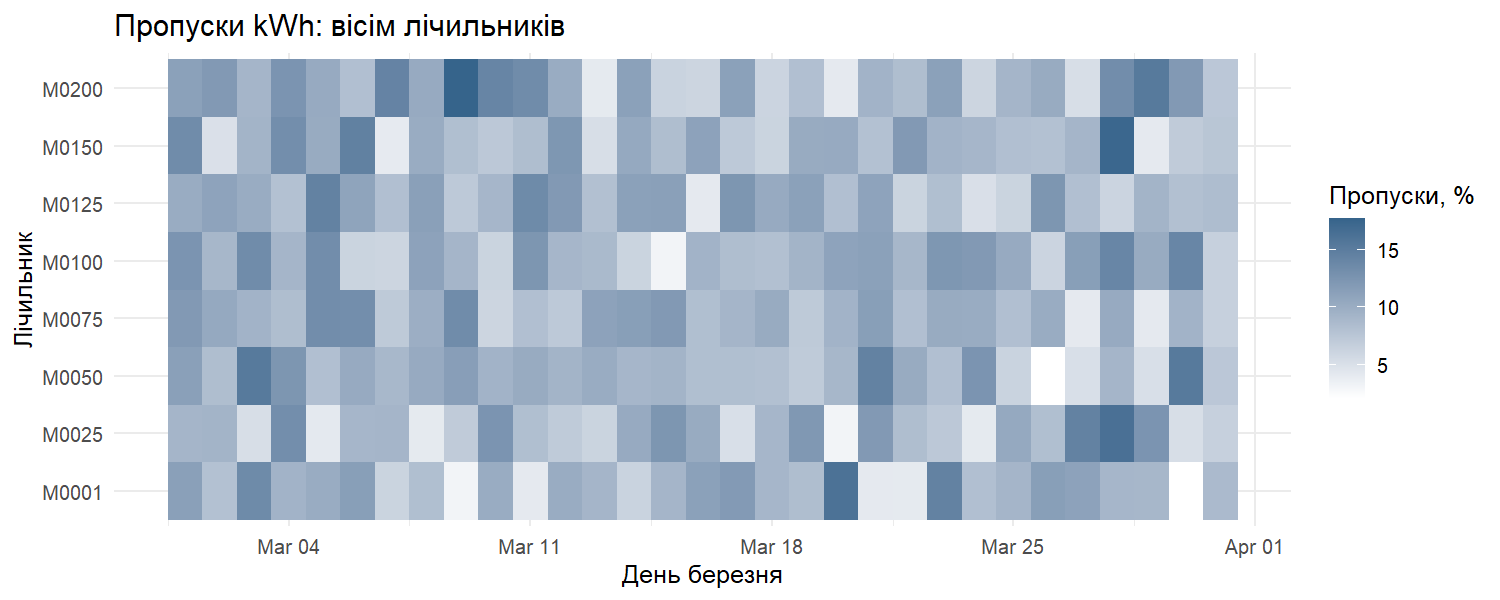

In [7]:
missing_map <- raw[meter_id %in% sample_meters,
  .(missing_percent=100*mean(is.na(kwh_num))),
  by=.(meter_id,day=as.Date(local_timestamp,tz=LOCAL_TZ))]
missing_plot <- ggplot(missing_map,aes(day,meter_id,fill=missing_percent))+geom_tile()+
  scale_fill_gradient(low="white",high="steelblue4")+
  labs(title="Пропуски kWh: вісім лічильників",x="День березня",y="Лічильник",fill="Пропуски, %")+
  theme_minimal(base_size=12)
ggsave("outputs/figures/missingness_8_meters.png",missing_plot,width=10,height=4,dpi=150)
print(missing_plot)



### Висновок до очистки
Накопичувальні показники, повтори й аномалії спотворюють середні та наївний рахунок. Пропуски залежать від часу доби і стану лічильника. UTC-записи потребують перетворення моменту часу перед перевіркою тарифу. Суцільні пропуски рядків неможливо побачити лише через `is.na(kwh)`, тому їх перевіряють відносно теоретичної часової сітки.



## 3. Очистка
Послідовність: числовий і текстовий парсинг → часові пояси → точні та логічні повтори → cumulative → interval → аномалії → повна сітка → короткі пропуски → тариф і ціна. Правила нормалізації тексту та числа ідемпотентні.

| Поле | Проблема | Правило | Очікуваний ефект | Примітка |
|---|---|---|---|---|
| Числові поля | Кома, пробіли, NBSP | `parse_dirty_number()` | Тип numeric | Не замінювати реальні NA нулем |
| `timestamp`, `tz` | UTC, два формати, DST | Парсинг instant і переведення до Kyiv | Єдина сітка | Не створювати неіснуючу годину 03:00 |
| `meter_id × timestamp` | Точні та часткові повтори | Повний збіг; далі OK > EST > OUTAGE, повнота | Один запис на слот | Перевірка ключа після вибору |
| `reading_type`, `kwh` | Накопичувальні серії | Різниця сусідніх counter, окреме правило rollover | Інтервальні kWh | Перший counter сегмента стає NA |
| `kwh` | Пропуски | Лінійна інтерполяція лише 1–4 слотів | Менше коротких NA | Довгі gap залишаються NA |
| `kwh` | Фізичні аномалії | Non-PV <0 → 0; максимум 15; PV мінімум −10 | Валідні межі | Прапорці зберігають факт виправлення |
| `voltage_v`, `power_factor` | Вихід за межі/NA | Обрізання; медіана meter → site → загальна | Валідні діапазони | Логи фіксують кількість |
| `city`, `quality_flag`, `note` | Регістр і пробіли | Канонізація та очищення тексту | Сталі категорії | Немає потреби вигадувати `Other` для трьох відомих міст |
| `tariff`, `price_uah_kwh` | UTC-тариф і хибна ціна | Локальна година; join з довідником | Узгоджений рахунок | T2 23:00–06:59 |



In [8]:
stopifnot(identical(normalize_city(normalize_city(c("kyiv","Lviv "))),normalize_city(c("kyiv","Lviv "))),
          identical(clean_note(clean_note(c(" PV  export "))),clean_note(c(" PV  export "))),
          identical(parse_dirty_number(as.character(parse_dirty_number(c("1 234,5")))),parse_dirty_number(c("1 234,5"))))
change_log <- data.table(step=character(),field=character(),rule=character(),changed_count=integer(),example_before=character(),example_after=character())
add_log <- function(step,field,rule,count,before="",after="") {
  change_log <<- rbind(change_log, data.table(step=step,field=field,rule=rule,changed_count=as.integer(count),
                                               example_before=as.character(before),example_after=as.character(after)))
}
clean <- copy(raw)
for (field in c("kwh","kvarh","voltage_v","current_a","price_uah_kwh")) {
  changed <- sum(grepl(",|[[:space:]\u00a0]",clean[[field]],perl=TRUE),na.rm=TRUE)
  set(clean,j=field,value=parse_dirty_number(clean[[field]]))
  add_log("числовий парсинг",field,"десяткова кома та пробіли",changed,"230,45","230.45")
}
old_city <- clean$city; clean[, city := normalize_city(city)]
add_log("категорії","city","канонічна назва",sum(old_city!=clean$city,na.rm=TRUE)," kyiv","Kyiv")
old_quality <- clean$quality_flag; clean[, quality_flag := normalize_quality_flag(quality_flag)]
add_log("категорії","quality_flag","trim та uppercase",sum(old_quality!=clean$quality_flag,na.rm=TRUE)," ok ","OK")
old_note <- clean$note; clean[, note := clean_note(note)]
add_log("текст","note","невидимі символи та пробіли",sum(old_note!=clean$note,na.rm=TRUE)," PV  export ","PV export")
clean[, timestamp := local_timestamp]
add_log("час","timestamp","UTC/локальний формат → Europe/Kyiv",sum(raw$tz=="UTC"),"UTC","Europe/Kyiv")
clean[, c("kwh_num","voltage_num","price_num","city_norm","local_timestamp","local_tariff","full_duplicate") := NULL]
before_full <- nrow(clean); clean <- unique(clean, by=names(clean))
add_log("повтори","усі поля","точний повтор",before_full-nrow(clean))
clean[, `:=`(quality_rank=fcase(quality_flag=="OK",3L,quality_flag=="EST",2L,default=1L),
             completeness=rowSums(!is.na(.SD))), .SDcols=setdiff(names(clean),c("quality_rank","completeness"))]
setorder(clean, meter_id,timestamp,-quality_rank,-completeness,record_id)
before_logical <- nrow(clean); clean <- unique(clean,by=c("meter_id","timestamp"))
add_log("повтори","meter_id × timestamp","OK > EST > OUTAGE; повнота; record_id",before_logical-nrow(clean))
clean[, c("quality_rank","completeness") := NULL]
setorder(clean,meter_id,timestamp)
stopifnot(!anyNA(clean$timestamp), uniqueN(clean,by=c("meter_id","timestamp"))==nrow(clean))



In [9]:
# Сегменти відділяються за зміною типу в межах кожного meter; перший counter без попередника лишається NA.
clean[, previous_type := shift(reading_type), by=meter_id]
clean[, segment_id := cumsum(is.na(previous_type) | reading_type != previous_type), by=meter_id]
clean[, previous_counter := shift(kwh), by=.(meter_id,segment_id)]
clean[, converted_from_cum := as.integer(reading_type=="cumulative")]
clean[, rollover := as.integer(reading_type=="cumulative" & !is.na(previous_counter) &
                                 !is.na(kwh) & previous_counter>9900 & kwh<100)]
clean[, interval_value := fifelse(is.na(previous_counter),NA_real_,
                                 fifelse(kwh>=previous_counter,kwh-previous_counter,
                                         fifelse(rollover==1,COUNTER_MAX-previous_counter+kwh,NA_real_)))]
converted_count <- sum(clean$converted_from_cum)
rollover_count <- sum(clean$rollover)
clean[reading_type=="cumulative", kwh := interval_value]
clean[, reading_type := "interval"]
clean[, c("previous_type","segment_id","previous_counter","interval_value") := NULL]
add_log("cumulative","kwh","різниця у сегменті; перший counter → NA",converted_count,"лічильник","інтервал")
add_log("rollover","kwh","COUNTER_MAX - previous + current",rollover_count,"9999 → 0","додатний інтервал")
clean[, invalid_neg := as.integer(!is.na(kwh) & pv_flag==0 & kwh<0)]
clean[, kwh_anomaly := as.integer(!is.na(kwh) & (kwh>15 | (pv_flag==1 & kwh< -10)))]
clean[invalid_neg==1, kwh := 0]
clean[, kwh := pmin(15,pmax(fifelse(pv_flag==1,-10,0),kwh))]
add_log("аномалії","kwh","non-PV <0 → 0",sum(clean$invalid_neg),"-5","0")
add_log("аномалії","kwh","межі PV [-10,15], non-PV [0,15]",sum(clean$kwh_anomaly),"30","15")
clean[, voltage_anomaly := as.integer(!is.na(voltage_v) & (voltage_v<180 | voltage_v>260))]
clean[, voltage_v := pmin(260,pmax(180,voltage_v))]
add_log("аномалії","voltage_v","обмеження [180,260]",sum(clean$voltage_anomaly),"310","260")
clean[, pf_anomaly := as.integer(!is.na(power_factor) & (power_factor<0 | power_factor>1))]
clean[, power_factor := pmin(1,pmax(0,power_factor))]
add_log("аномалії","power_factor","обмеження [0,1]",sum(clean$pf_anomaly),"1.25","1")



In [10]:
# Повна сітка повертає фізично вилучені записи. Структурний gap надалі означає невідновлене значення kWh.
complete_grid <- CJ(meter_id=meters$meter_id,timestamp=time_grid)
setkey(clean,meter_id,timestamp)
clean <- clean[complete_grid, on=.(meter_id,timestamp)]
new_rows <- is.na(clean$record_id)
new_count <- sum(new_rows)
clean[new_rows, record_id := paste0("SYN-",meter_id,"-",format(timestamp,"%Y%m%d%H%M",tz=LOCAL_TZ))]
clean[new_rows, `:=`(converted_from_cum=0L,rollover=0L,invalid_neg=0L,kwh_anomaly=0L,
                     voltage_anomaly=0L,pf_anomaly=0L,reading_type="interval",quality_flag="OUTAGE",note="structural gap")]
for (field in c("site_id","city","pv_flag")) {
  reference <- meters[[field]][match(clean$meter_id,meters$meter_id)]
  set(clean,i=which(new_rows),j=field,value=reference[new_rows])
}
add_log("повна сітка","record_id","повернення відсутніх slot",new_count,"рядок відсутній",clean[new_rows,record_id][1])
# 200 циклів по лічильниках: approx використовується лише для runs довжиною <=4 з двома сусідами.
impute_meter <- function(x) {
  missing <- is.na(x); runs <- rle(missing)
  lengths <- rep(runs$lengths,runs$lengths)
  ends <- cumsum(runs$lengths); starts <- ends-runs$lengths+1L
  eligible <- rep(FALSE,length(x))
  for (j in which(runs$values & runs$lengths<=4L)) {
    a <- starts[j]; b <- ends[j]
    if (a>1L && b<length(x) && !is.na(x[a-1L]) && !is.na(x[b+1L])) eligible[a:b] <- TRUE
  }
  if (any(eligible)) {
    valid <- which(!missing)
    x[eligible] <- approx(valid,x[valid],xout=which(eligible),rule=1)$y
  }
  list(value=x,imputed=as.integer(eligible))
}
clean[, c("kwh","imputed_short_gap") := impute_meter(kwh), by=meter_id]
clean[, gap := as.integer(is.na(kwh))]
clean[imputed_short_gap==1, quality_flag := "EST"]
clean[gap==1, quality_flag := "OUTAGE"]
add_log("пропуски","kwh","лінійна інтерполяція run <=4",sum(clean$imputed_short_gap),"NA","інтерполяція")
add_log("пропуски","gap","довгий або крайовий run лишається NA",sum(clean$gap),"NA","gap=1")
# Каскадна медіана: meter → site → global.
for (field in c("voltage_v","power_factor")) {
  missing_before <- sum(is.na(clean[[field]]))
  meter_med <- clean[, .(v=median(get(field),na.rm=TRUE)), by=meter_id]
  site_med <- clean[, .(v=median(get(field),na.rm=TRUE)), by=site_id]
  value <- clean[[field]]
  fill <- meter_med$v[match(clean$meter_id,meter_med$meter_id)]
  site_fill <- site_med$v[match(clean$site_id,site_med$site_id)]
  fill[!is.finite(fill)] <- site_fill[!is.finite(fill)]
  fill[!is.finite(fill)] <- median(value,na.rm=TRUE)
  value[is.na(value)] <- fill[is.na(value)]
  set(clean,j=field,value=value)
  add_log("пропуски",field,"median meter → site → global",missing_before,"NA","медіана")
}
correct_tariff <- fifelse(hour(clean$timestamp)>=23 | hour(clean$timestamp)<7,"T2","T1")
clean[, tariff_corrected := as.integer(is.na(tariff) | tariff!=correct_tariff)]
clean[, tariff := correct_tariff]
add_log("тариф","tariff","локальна година Києва",sum(clean$tariff_corrected),"UTC тариф","T1/T2")
price_ref <- tariff_ref$price_uah_kwh[match(paste(clean$site_id,clean$tariff),paste(tariff_ref$site_id,tariff_ref$tariff))]
price_changed <- sum(is.na(clean$price_uah_kwh) | abs(clean$price_uah_kwh-price_ref)>1e-8)
clean[, price_uah_kwh := price_ref]
add_log("ціна","price_uah_kwh","site_id + tariff reference",price_changed,"raw","довідник")
clean[, tz := LOCAL_TZ]
setorder(clean,meter_id,timestamp)
export_clean <- copy(clean)
export_clean[, timestamp := format(timestamp,"%Y-%m-%d %H:%M:%S",tz=LOCAL_TZ)]
fwrite(export_clean,"data/clean/dataset_clean.csv",na="")
fwrite(change_log,"change_log.csv")
cat("Записано clean rows:",nrow(clean),"; log steps:",nrow(change_log),"\n")



Записано clean rows: 594400 ; log steps: 24 


### 3.1 Валідація
Кожен тест повертає PASS або FAIL; критична помилка зупиняє виконання.



In [11]:
checks <- c(
  "Унікальний record_id"=uniqueN(clean$record_id)==nrow(clean),
  "Унікальний meter × timestamp"=uniqueN(clean,by=c("meter_id","timestamp"))==nrow(clean),
  "POSIXct timestamp"=inherits(clean$timestamp,"POSIXct") && !anyNA(clean$timestamp),
  "Часовий пояс Київ"=identical(attr(clean$timestamp,"tzone"),LOCAL_TZ),
  "Всі interval"=all(clean$reading_type=="interval"),
  "Cumulative конвертовано"=all(clean$converted_from_cum %in% 0:1) && any(clean$converted_from_cum==1),
  "Non-PV kWh"=all(clean[pv_flag==0 & !is.na(kwh),kwh]>=0),
  "PV kWh"=all(clean[pv_flag==1 & !is.na(kwh),kwh]>= -10),
  "Верхня межа kWh"=all(clean[!is.na(kwh),kwh]<=15),
  "Напруга [180,260]"=all(clean$voltage_v>=180 & clean$voltage_v<=260),
  "PF [0,1]"=all(clean$power_factor>=0 & clean$power_factor<=1),
  "Quality categories"=all(clean$quality_flag %in% c("OK","EST","OUTAGE")),
  "City categories"=all(clean$city %in% CITIES),
  "Tariff categories"=all(clean$tariff %in% c("T1","T2")),
  "Тариф за місцевим часом"=all(clean$tariff==fifelse(hour(clean$timestamp)>=23 | hour(clean$timestamp)<7,"T2","T1")),
  "Ціна за довідником"=all(abs(clean$price_uah_kwh-price_ref)<1e-8),
  "Повна сітка"=nrow(clean)==N_METERS*length(time_grid) && all(clean[, .N,by=meter_id]$N==length(time_grid)),
  "DST без хибної години"=!any(format(clean$timestamp,"%Y-%m-%d %H",tz=LOCAL_TZ)=="2024-03-31 03"),
  "Неімпутовані gap"=all(is.na(clean[gap==1,kwh])) && all(clean[gap==1,imputed_short_gap]==0),
  "PV експорт збережено"=any(clean[pv_flag==1 & !is.na(kwh),kwh]<0))
validation <- data.table(number=seq_along(checks),check=names(checks),status=fifelse(checks,"PASS","FAIL"),details=as.character(checks))
print(validation)
fwrite(validation,"outputs/validation_checks.csv")
stopifnot(all(checks))



    number                        check status details
     <int>                       <char> <char>  <char>
 1:      1         Унікальний record_id   PASS    TRUE
 2:      2 Унікальний meter × timestamp   PASS    TRUE
 3:      3            POSIXct timestamp   PASS    TRUE
 4:      4            Часовий пояс Київ   PASS    TRUE
 5:      5                 Всі interval   PASS    TRUE
 6:      6      Cumulative конвертовано   PASS    TRUE
 7:      7                   Non-PV kWh   PASS    TRUE
 8:      8                       PV kWh   PASS    TRUE
 9:      9              Верхня межа kWh   PASS    TRUE
10:     10            Напруга [180,260]   PASS    TRUE
11:     11                     PF [0,1]   PASS    TRUE
12:     12           Quality categories   PASS    TRUE
13:     13              City categories   PASS    TRUE
14:     14            Tariff categories   PASS    TRUE
15:     15      Тариф за місцевим часом   PASS    TRUE
16:     16           Ціна за довідником   PASS    TRUE
17:     17

## 4. Статистика після очистки та графіки
Довгі прогалини залишаються NA і не входять до середніх. Накопичувальні значення вже перетворені на інтервальну енергію.



     city      n  kwh_mean kwh_median   kwh_p95 voltage_mean  missing_kwh
   <char>  <int>     <num>      <num>     <num>        <num>        <num>
1:   Kyiv 202096 0.5680570     0.4401 0.8921000     229.8006 0.0007768585
2:   Lviv 202096 0.5425163     0.4282 0.8213000     229.9445 0.0005987254
3:  Odesa 190208 0.5461123     0.4215 0.8105925     229.8669 0.0006519179
Числова статистика після очистки:
           field valid_n        mean      median         sd     min      max
          <char>   <int>       <num>       <num>      <num>   <num>    <num>
1:           kwh  593998   0.5523500   0.4297833 1.26703109 -10.000  15.0000
2:         kvarh  594130   0.1781913   0.1637000 0.08772534   0.000   0.8243
3:     voltage_v  594400 229.8707539 229.9425000 5.92864217 180.000 260.0000
4:     current_a  594130   8.5519533   8.0590000 3.73554702   0.000  30.2439
5:  power_factor  594400   0.9285254   0.9300000 0.04613724   0.000   1.0000
6: price_uah_kwh  594400   3.8316862   4.0910000 0.888750

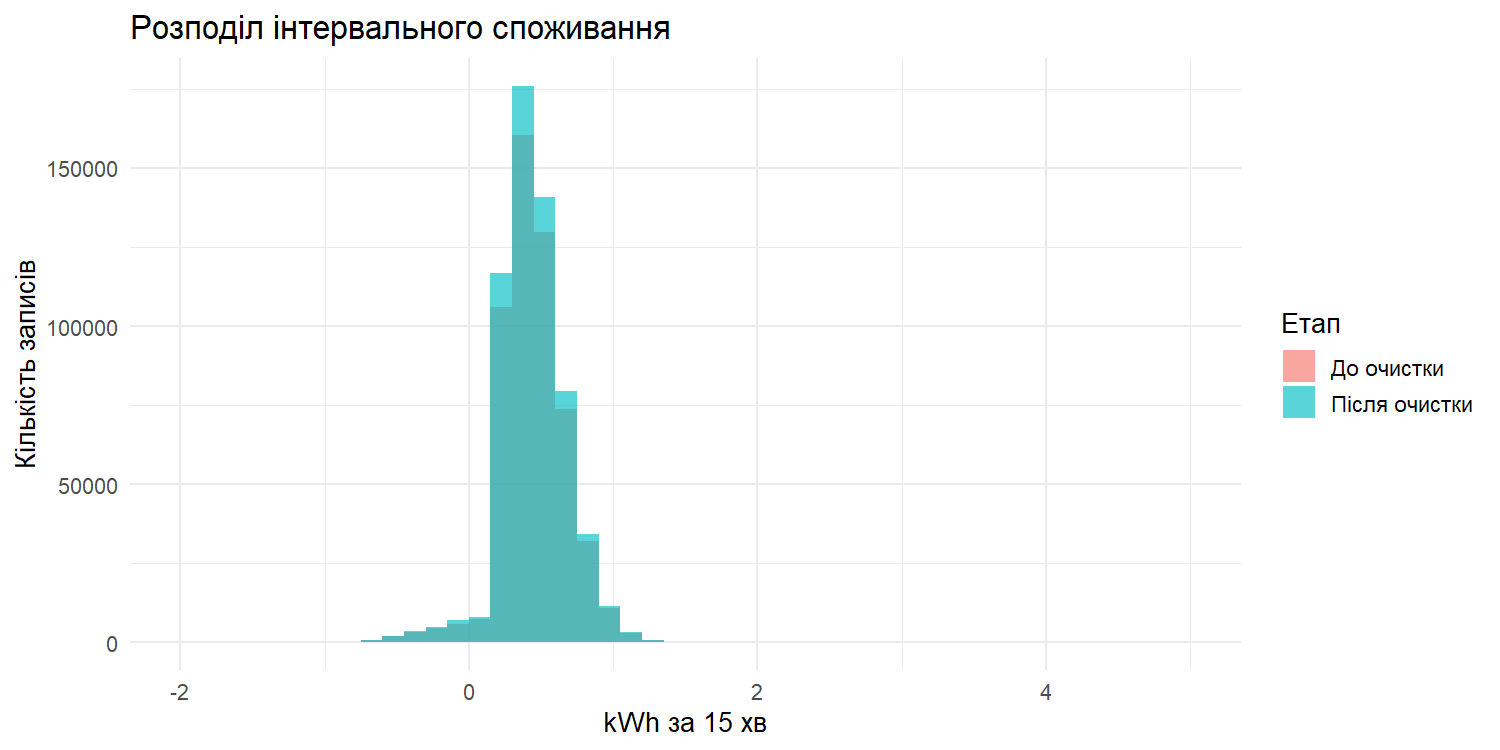

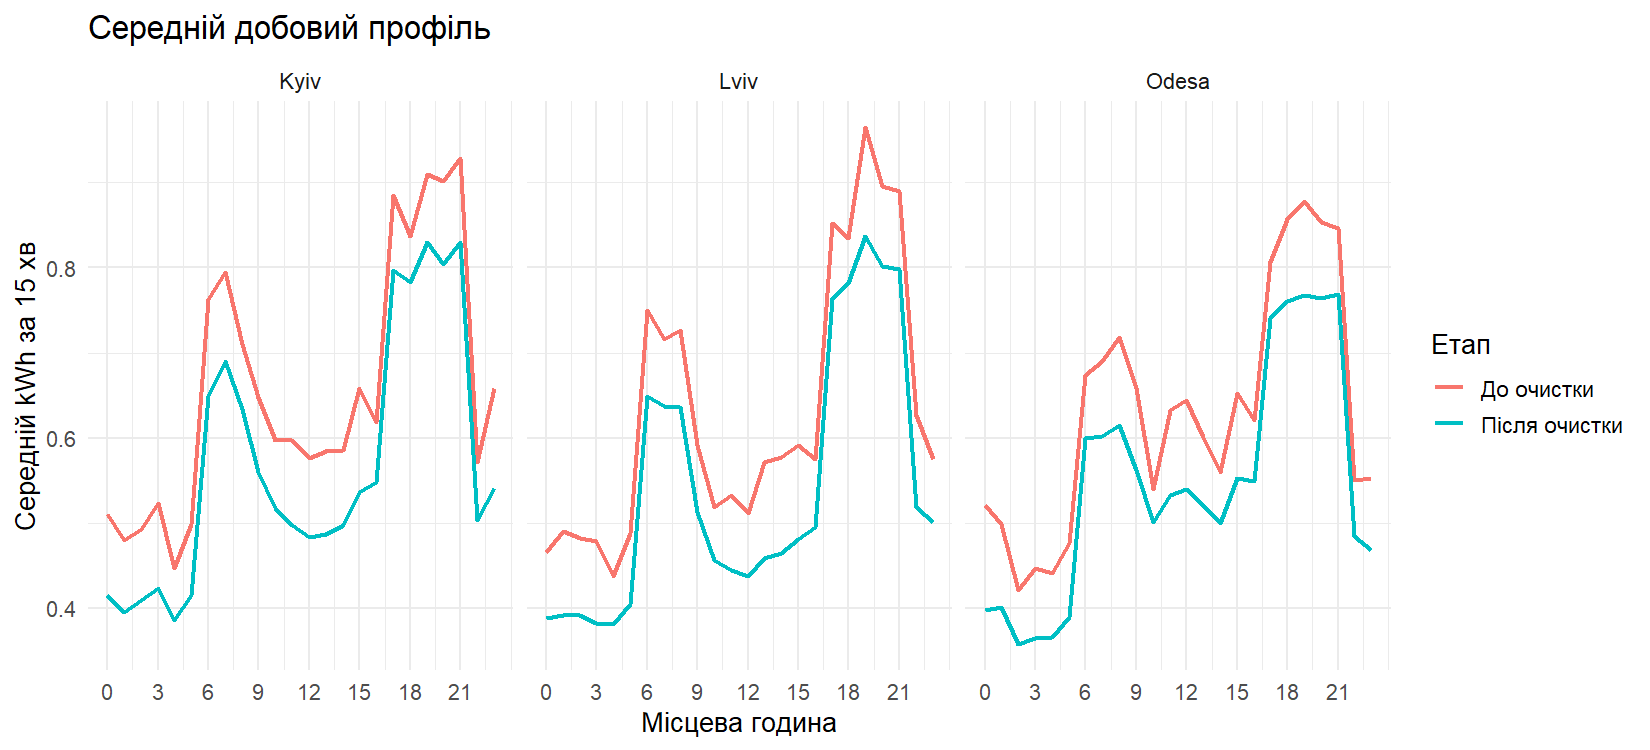

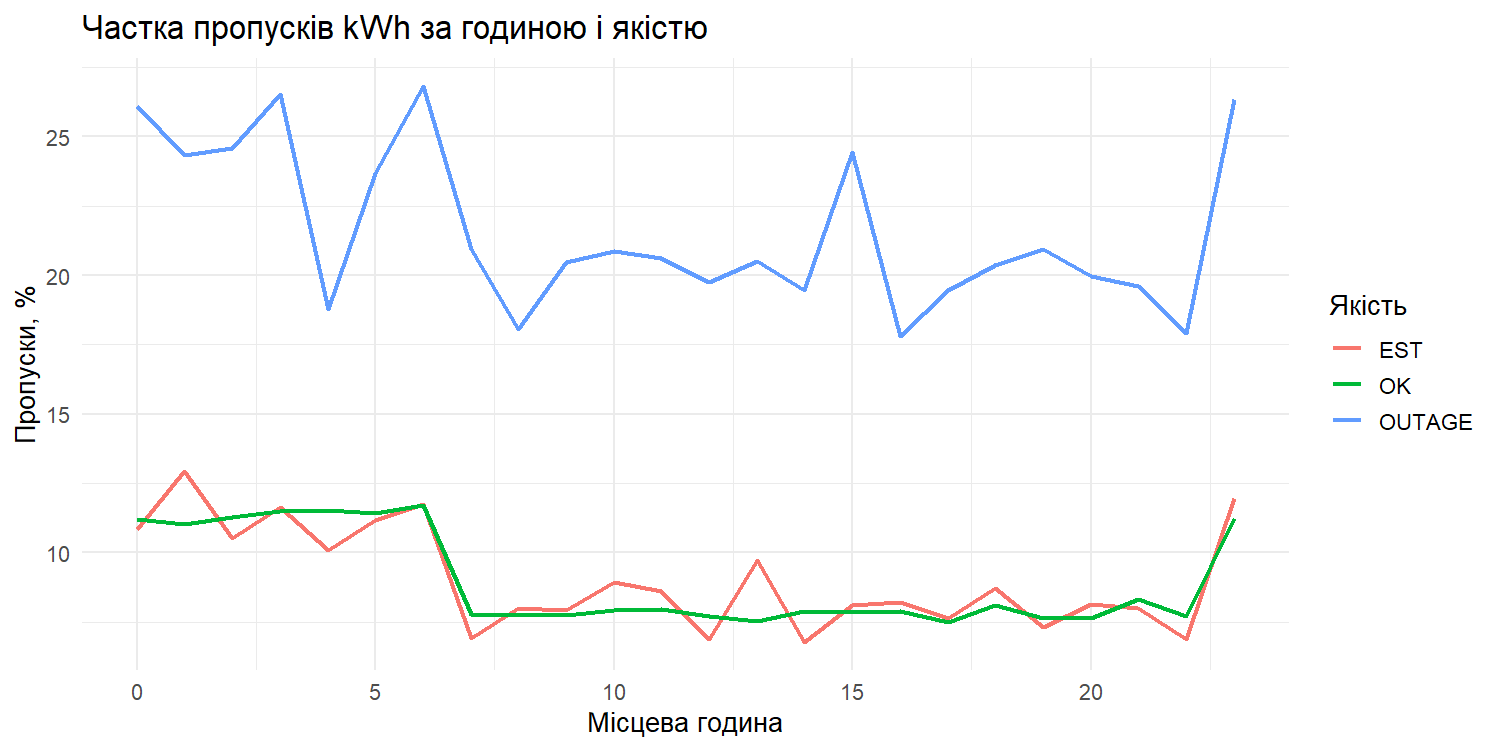

In [12]:
after_stats <- clean[, .(n=.N, kwh_mean=mean(kwh,na.rm=TRUE),kwh_median=median(kwh,na.rm=TRUE),
                         kwh_p95=as.numeric(quantile(kwh,.95,na.rm=TRUE)),
                         voltage_mean=mean(voltage_v),missing_kwh=mean(is.na(kwh))),by=city]
print(after_stats)
clean_numeric_diagnostics <- summarise_numeric(list(
  kwh=clean$kwh,kvarh=clean$kvarh,voltage_v=clean$voltage_v,
  current_a=clean$current_a,power_factor=clean$power_factor,
  price_uah_kwh=clean$price_uah_kwh))
clean_missing_diagnostics <- missing_diagnostics(clean)
cat("Числова статистика після очистки:\n"); print(clean_numeric_diagnostics)
cat("Пропуски за всіма полями після очистки:\n"); print(clean_missing_diagnostics)
before_after <- merge(raw_numeric_summary,after_stats,by.x="city_norm",by.y="city",suffixes=c("_before","_after"))
print(before_after)
quality_comparison <- data.table(
  metric=c("Рядки","Пропуски kWh, %","Пропуски напруги, %","Повтори meter × time",
           "Cumulative rows","Non-PV негативи","Напруга поза [180,260]","Хибний tariff"),
  before=c(nrow(raw),100*mean(is.na(raw$kwh_num)),100*mean(is.na(raw$voltage_num)),
           logical_duplicates,sum(raw$reading_type=="cumulative"),
           sum(raw$pv_flag==0 & raw$kwh_num<0,na.rm=TRUE),
           sum(raw$voltage_num<180 | raw$voltage_num>260,na.rm=TRUE),
           sum(raw$tariff!=raw$local_tariff,na.rm=TRUE)),
  after=c(nrow(clean),100*mean(is.na(clean$kwh)),100*mean(is.na(clean$voltage_v)),
          nrow(clean)-uniqueN(clean,by=c("meter_id","timestamp")),
          sum(clean$reading_type=="cumulative"),
          sum(clean$pv_flag==0 & clean$kwh<0,na.rm=TRUE),
          sum(clean$voltage_v<180 | clean$voltage_v>260,na.rm=TRUE),
          sum(clean$tariff!=fifelse(hour(clean$timestamp)>=23 | hour(clean$timestamp)<7,"T2","T1"))))
cat("Порівняння якості до і після:\n"); print(quality_comparison)
fwrite(quality_comparison,"outputs/before_after_quality.csv")
plot_before <- raw[reading_type=="interval" & !is.na(kwh_num),.(kwh=kwh_num,stage="До очистки")]
plot_after <- clean[!is.na(kwh),.(kwh,stage="Після очистки")]
plot_data <- rbind(plot_before,plot_after)
p1 <- ggplot(plot_data,aes(x=kwh,fill=stage))+geom_histogram(binwidth=.15,boundary=0,alpha=.65,position="identity")+
  coord_cartesian(xlim=c(-2,5))+labs(title="Розподіл інтервального споживання",x="kWh за 15 хв",y="Кількість записів",fill="Етап")+theme_minimal(base_size=13)
ggsave("outputs/figures/kwh_before_after.png",p1,width=10,height=5,dpi=150)
raw_profile <- raw[reading_type=="interval" & !is.na(kwh_num),.(kwh=mean(kwh_num)),by=.(city=city_norm,hour=hour(local_timestamp))][,stage:="До очистки"]
clean_profile <- clean[!is.na(kwh),.(kwh=mean(kwh)),by=.(city,hour=hour(timestamp))][,stage:="Після очистки"]
p2 <- ggplot(rbind(raw_profile,clean_profile),aes(x=hour,y=kwh,color=stage))+geom_line(linewidth=1)+
  facet_wrap(~city)+scale_x_continuous(breaks=seq(0,23,3))+labs(title="Середній добовий профіль",x="Місцева година",y="Середній kWh за 15 хв",color="Етап")+theme_minimal(base_size=13)
ggsave("outputs/figures/daily_profile_before_after.png",p2,width=11,height=5,dpi=150)
missing_by_hour <- raw[, .(missing_share=mean(is.na(kwh_num))),by=.(hour=hour(local_timestamp),quality_flag=normalize_quality_flag(quality_flag))]
p3 <- ggplot(missing_by_hour,aes(hour,100*missing_share,color=quality_flag))+geom_line(linewidth=1)+
  labs(title="Частка пропусків kWh за годиною і якістю",x="Місцева година",y="Пропуски, %",color="Якість")+theme_minimal(base_size=13)
ggsave("outputs/figures/missingness_by_hour.png",p3,width=10,height=5,dpi=150)
print(p1); print(p2); print(p3)
cat(sprintf("Після очистки %d рядків, %d коротких імпутацій, %d довгих/крайових gap.\n",nrow(clean),sum(clean$imputed_short_gap),sum(clean$gap)))



### Висновок після очистки
Порівняння нижче використовує лише фактично обчислені числа; позначені довгі прогалини залишаються обмеженням аналізу.



In [13]:
comparison_conclusion <- sprintf(paste(
  "Кількість записів змінилася з %d до %d після видалення повторів і відновлення повної сітки.",
  "Логічних повторів було %d, а після очистки їх %d.",
  "Пропуски kWh зменшилися з %.2f%% до %.2f%% завдяки інтерполяції лише коротких послідовностей.",
  "Залишилося %d довгих або крайових прогалин із gap=1, тому доступність не дорівнює 100%%.",
  "До інтервального формату переведено %d накопичувальних показників і правильно оброблено %d rollover.",
  "Після очистки немає від'ємних non-PV kWh, напруги поза межами та тарифів, що суперечать місцевому часу.",
  "Сума тарифних виправлень становить %d записів; фінансовий наслідок обчислюється окремо в KPI 10."),
  nrow(raw),nrow(clean),logical_duplicates,
  nrow(clean)-uniqueN(clean,by=c("meter_id","timestamp")),
  100*mean(is.na(raw$kwh_num)),100*mean(is.na(clean$kwh)),sum(clean$gap),
  converted_count,rollover_count,sum(clean$tariff_corrected))
cat(comparison_conclusion,"\n")
writeLines(comparison_conclusion,"outputs/comparison_conclusion.txt",useBytes=TRUE)



Кількість записів змінилася з 604835 до 594400 після видалення повторів і відновлення повної сітки. Логічних повторів було 10705, а після очистки їх 0. Пропуски kWh зменшилися з 9.18% до 0.07% завдяки інтерполяції лише коротких послідовностей. Залишилося 402 довгих або крайових прогалин із gap=1, тому доступність не дорівнює 100%. До інтервального формату переведено 4314 накопичувальних показників і правильно оброблено 1 rollover. Після очистки немає від'ємних non-PV kWh, напруги поза межами та тарифів, що суперечать місцевому часу. Сума тарифних виправлень становить 20146 записів; фінансовий наслідок обчислюється окремо в KPI 10. 


### Порівняльний висновок

- Кількість записів змінилася з 604835 до 594400 після видалення повторів і відновлення повної сітки.
- Логічних повторів було 10705, а після очистки їх 0.
- Пропуски kWh зменшилися з 9.18% до 0.07% завдяки інтерполяції лише коротких послідовностей.
- Залишилося 402 довгих або крайових прогалин із gap=1, тому доступність не дорівнює 100%.
- До інтервального формату переведено 4314 накопичувальних показників і правильно оброблено 1 rollover.
- Після очистки немає від'ємних non-PV kWh, напруги поза межами та тарифів, що суперечать місцевому часу.
- Сума тарифних виправлень становить 20146 записів; фінансовий наслідок обчислюється окремо в KPI 10.


## 5. Десять KPI
Для фінансових показників береться лише додатне споживання. Від'ємний PV експорт не зменшує рахунок, бо модель продажу енергії не задана.



In [14]:
clean[, billable_kwh := pmax(kwh,0)]


Key: <meter_id, timestamp>
Indices: <imputed_short_gap>, <gap>
        record_id meter_id site_id   city           timestamp          tz
           <char>   <char>  <char> <char>              <POSc>      <char>
     1:  R0000001    M0001    S001   Kyiv 2024-03-01 00:00:00 Europe/Kyiv
     2:  R0000002    M0001    S001   Kyiv 2024-03-01 00:15:00 Europe/Kyiv
     3:  R0000003    M0001    S001   Kyiv 2024-03-01 00:30:00 Europe/Kyiv
     4:  R0000004    M0001    S001   Kyiv 2024-03-01 00:45:00 Europe/Kyiv
     5:  R0000005    M0001    S001   Kyiv 2024-03-01 01:00:00 Europe/Kyiv
    ---                                                                  
594396:  R0594136    M0200    S050   Lviv 2024-03-31 22:45:00 Europe/Kyiv
594397:  R0594137    M0200    S050   Lviv 2024-03-31 23:00:00 Europe/Kyiv
594398:  R0594138    M0200    S050   Lviv 2024-03-31 23:15:00 Europe/Kyiv
594399:  R0594139    M0200    S050   Lviv 2024-03-31 23:30:00 Europe/Kyiv
594400:  R0594140    M0200    S050   Lviv 2024-03

### KPI 1. Середнє добове споживання на лічильник


In [15]:
daily <- clean[, .(daily_kwh=sum(kwh,na.rm=TRUE)),by=.(city,meter_id,date=as.Date(timestamp,tz=LOCAL_TZ))]
kpi1 <- daily[, .(mean_daily_kwh_per_meter=mean(daily_kwh),median_daily_kwh_per_meter=median(daily_kwh)),by=city]


### KPI 2. Частка споживання за нічним тарифом


In [16]:
kpi2 <- clean[, .(t2_share_percent=100*sum(billable_kwh[tariff=="T2"],na.rm=TRUE)/sum(billable_kwh,na.rm=TRUE)),by=.(city,site_id)]
kpi2_total <- 100*clean[tariff=="T2",sum(billable_kwh,na.rm=TRUE)]/sum(clean$billable_kwh,na.rm=TRUE)


### KPI 3. Економія від T2 порівняно з T1


In [17]:
t1_price <- tariff_ref[tariff=="T1",price_uah_kwh][match(clean$site_id,tariff_ref[tariff=="T1",site_id])]
clean[, saving_uah := fifelse(tariff=="T2",billable_kwh*(t1_price-price_uah_kwh),0)]
kpi3 <- clean[, .(saving_uah=sum(saving_uah,na.rm=TRUE),actual_cost=sum(billable_kwh*price_uah_kwh,na.rm=TRUE)),by=city]
kpi3[, saving_percent := 100*saving_uah/actual_cost]
kpi3_total <- kpi3[, .(city="Усього",saving_uah=sum(saving_uah),actual_cost=sum(actual_cost))]
kpi3_total[, saving_percent := 100*saving_uah/actual_cost]


     city saving_uah actual_cost saving_percent
   <char>      <num>       <num>          <num>
1: Усього   148860.8     1319154       11.28456


### KPI 4. Частка інтервалів з експортом PV


In [18]:
kpi4 <- clean[pv_flag==1 & !is.na(kwh),.(pv_export_share_percent=100*mean(kwh<0)),by=city]
kpi4_total <- clean[pv_flag==1 & !is.na(kwh),100*mean(kwh<0)]


### KPI 5. Часова доступність вимірювань


In [19]:
availability_meter <- clean[, .(availability_percent=100*sum(!is.na(kwh))/length(time_grid)),by=.(city,meter_id)]
kpi5 <- availability_meter[, .(mean_availability_percent=mean(availability_percent),median_availability_percent=median(availability_percent)),by=city]


### KPI 6. Внесок накопичувальних показників


In [20]:
kpi6 <- data.table(converted_rows_share_percent=100*clean[!is.na(kwh),mean(converted_from_cum==1)],
                   converted_energy_share_percent=100*clean[converted_from_cum==1,sum(billable_kwh,na.rm=TRUE)]/sum(clean$billable_kwh,na.rm=TRUE))


### KPI 7. Дев'яносто п'ятий перцентиль до та після


In [21]:
p95_before <- raw[reading_type=="interval",.(p95_before=as.numeric(quantile(kwh_num,.95,na.rm=TRUE))),by=.(city=city_norm)]
p95_after <- clean[,.(p95_after=as.numeric(quantile(kwh,.95,na.rm=TRUE))),by=city]
kpi7 <- merge(p95_before,p95_after,by="city")
kpi7[, `:=`(difference=p95_after-p95_before,difference_percent=100*(p95_after-p95_before)/p95_before)]


Key: <city>
     city p95_before p95_after difference difference_percent
   <char>      <num>     <num>      <num>              <num>
1:   Kyiv     0.8943 0.8921000 -0.0022000         -0.2460025
2:   Lviv     0.8227 0.8213000 -0.0014000         -0.1701714
3:  Odesa     0.8122 0.8105925 -0.0016075         -0.1979192


### KPI 8. Частки EST і OUTAGE


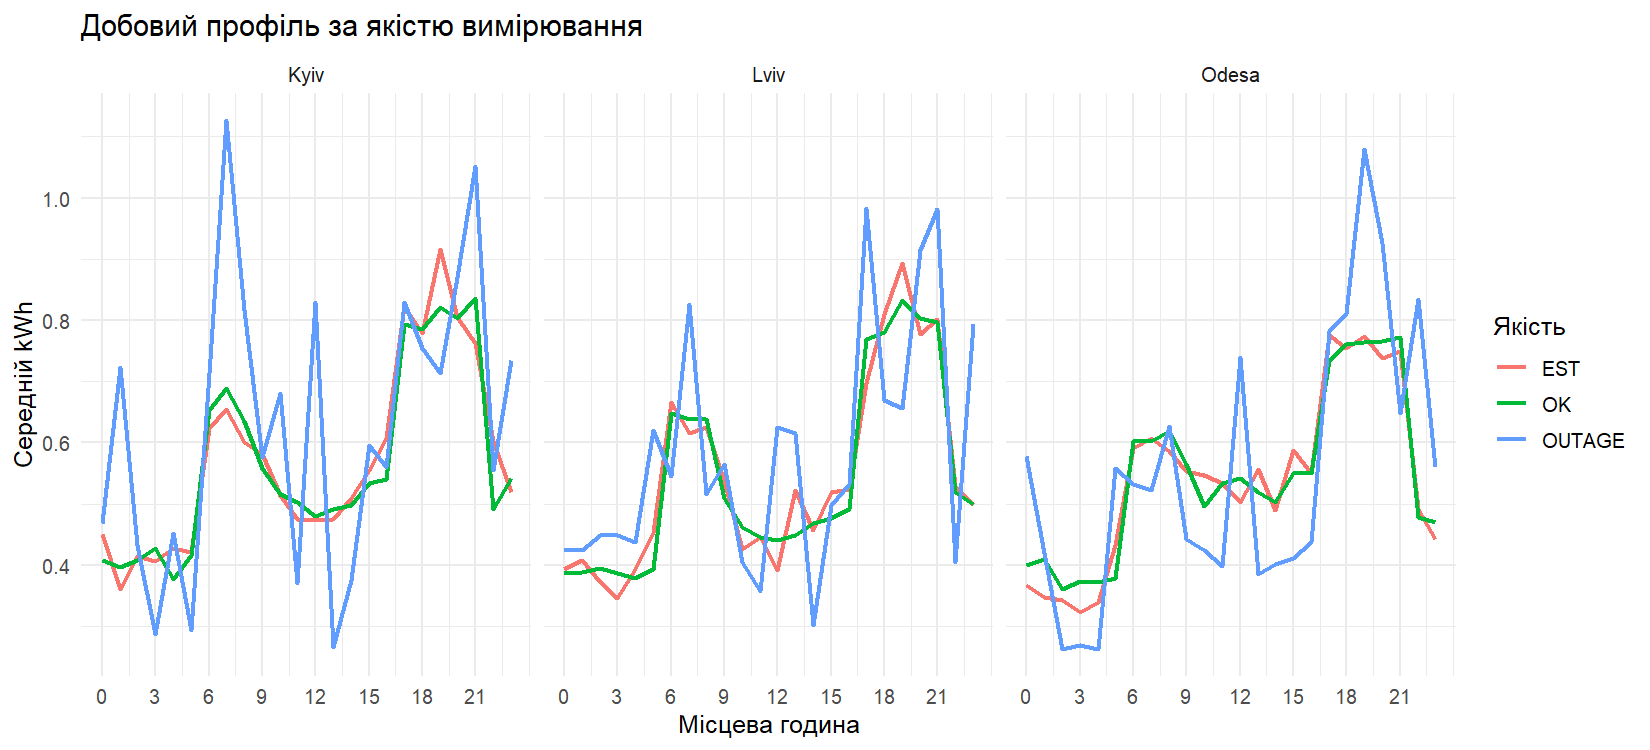

In [22]:
kpi8 <- clean[, .(n=.N,mean_kwh=mean(kwh,na.rm=TRUE)),by=.(city,quality_flag)]
kpi8[, share_percent := 100*n/sum(n),by=city]
kpi8_profile <- clean[!is.na(kwh),
  .(mean_kwh=mean(kwh)),by=.(city,quality_flag,hour=hour(timestamp))]
kpi8_plot <- ggplot(kpi8_profile,aes(hour,mean_kwh,color=quality_flag))+geom_line(linewidth=.9)+
  facet_wrap(~city)+scale_x_continuous(breaks=seq(0,23,3))+
  labs(title="Добовий профіль за якістю вимірювання",x="Місцева година",y="Середній kWh",color="Якість")+
  theme_minimal(base_size=12)
ggsave("outputs/figures/quality_profile.png",kpi8_plot,width=11,height=5,dpi=150)
print(kpi8_plot)


### KPI 9. Напруга до та після


In [23]:
volt_before <- raw[,.(mean_before=mean(voltage_num,na.rm=TRUE),median_before=median(voltage_num,na.rm=TRUE),
                       outside_before_percent=100*mean(voltage_num<180 | voltage_num>260,na.rm=TRUE)),by=.(city=city_norm)]
volt_after <- clean[,.(mean_after=mean(voltage_v),median_after=median(voltage_v),
                        outside_after_percent=100*mean(voltage_v<180 | voltage_v>260)),by=city]
kpi9 <- merge(volt_before,volt_after,by="city")


### KPI 10. Вартість: наївна оцінка raw і clean


In [24]:
raw_cost <- raw[,.(raw_cost_uah=sum(pmax(kwh_num,0)*price_num,na.rm=TRUE)),by=.(city=city_norm)]
clean_cost <- clean[,.(clean_cost_uah=sum(billable_kwh*price_uah_kwh,na.rm=TRUE)),by=city]
kpi10 <- merge(raw_cost,clean_cost,by="city")
kpi10[, `:=`(difference_uah=clean_cost_uah-raw_cost_uah,
             difference_percent=100*(clean_cost_uah-raw_cost_uah)/raw_cost_uah)]
kpi10_total <- kpi10[, .(city="Усього",raw_cost_uah=sum(raw_cost_uah),clean_cost_uah=sum(clean_cost_uah),
                         difference_uah=sum(difference_uah))]
kpi10_total[, difference_percent := 100*difference_uah/raw_cost_uah]


Key: <city>
     city raw_cost_uah clean_cost_uah difference_uah difference_percent
   <char>        <num>          <num>          <num>              <num>
1: Усього     69237601        1319154      -67918447          -98.09474


### Підсумок десяти KPI


In [25]:
for (i in 1:10) {cat("\nKPI",i,"\n"); print(get(paste0("kpi",i)))}
cat("\nKPI 2, загальна частка T2:",round(kpi2_total,2),"%\n")
cat("KPI 3, загалом:\n"); print(kpi3_total)
cat("KPI 4, загальна частка PV експорту:",round(kpi4_total,2),"%\n")
cat("KPI 10, загалом:\n"); print(kpi10_total)
kpi_summary <- data.table(KPI=1:10,
  name=c("Добове споживання","Частка T2","Економія T2","PV експорт","Доступність","Внесок cumulative","P95","EST/OUTAGE","Напруга","Вартість"),
  result=c(sprintf("%.3f kWh/день",mean(kpi1$mean_daily_kwh_per_meter)),
    sprintf("%.2f%%",kpi2_total),sprintf("%.2f грн",kpi3_total$saving_uah),
    sprintf("%.2f%%",kpi4_total),sprintf("%.2f%%",mean(availability_meter$availability_percent)),
    sprintf("%.2f%% рядків",kpi6$converted_rows_share_percent),sprintf("%.3f kWh",as.numeric(quantile(clean$kwh,.95,na.rm=TRUE))),
    sprintf("EST %.2f%%; OUTAGE %.2f%%",100*mean(clean$quality_flag=="EST"),100*mean(clean$quality_flag=="OUTAGE")),
    sprintf("поза межею %.2f%%",mean(kpi9$outside_after_percent)),sprintf("%.2f грн",kpi10_total$clean_cost_uah)),
  comment=c("на один meter","додатне споживання","порівняння з T1","частка валідних PV-інтервалів",
                     "2972 теоретичні слоти","конвертовані показники","до/після","за категорією якості",
                     "до/після","naive raw проти clean"))
setnames(kpi_summary,c("KPI","Назва","Основний результат","Короткий коментар"))
fwrite(kpi_summary,"outputs/kpi_summary.csv")
print(kpi_summary)




KPI 1 
     city mean_daily_kwh_per_meter median_daily_kwh_per_meter
   <char>                    <num>                      <num>
1:   Kyiv                 54.41787                   54.00770
2:   Lviv                 51.98043                   50.36320
3:  Odesa                 52.32218                   49.98235

KPI 2 
      city site_id t2_share_percent
    <char>  <char>            <num>
 1:   Kyiv    S001         25.73568
 2:   Lviv    S002         25.03833
 3:  Odesa    S003         24.00643
 4:   Kyiv    S004         27.57176
 5:   Lviv    S005         24.17380
 6:  Odesa    S006         24.85176
 7:   Kyiv    S007         26.37710
 8:   Lviv    S008         28.33643
 9:  Odesa    S009         25.73069
10:   Kyiv    S010         23.32237
11:   Lviv    S011         24.79508
12:  Odesa    S012         26.31720
13:   Kyiv    S013         24.21653
14:   Lviv    S014         26.02387
15:  Odesa    S015         26.01110
16:   Kyiv    S016         26.04009
17:   Lviv    S017        

## 6. Загальний висновок
Числа нижче формуються під час виконання, тому відповідають записаним CSV.



In [26]:
conclusion <- sprintf(paste(
  "Створено %d лічильників на %d об'єктах і %d сирих записів.",
  "Навмисно внесено пропуски, повні та часткові повтори, текстові числа й аномалії.",
  "Сирі пропуски kWh становили %.2f%%, а після побудови сітки залишилося %d невідновлених інтервалів.",
  "UTC і локальний час приведено до Europe/Kyiv; перехід DST дає %d інтервали замість 2976.",
  "Перетворено %d накопичувальних записів; виявлено %d rollover.",
  "Обмежено %d аномалій kWh і %d аномалій напруги.",
  "Виправлено %d тарифних записів за місцевою годиною та ціни за довідником.",
  "Наївна оцінка рахунку %.2f грн, очищена %.2f грн; різниця %.2f грн.",
  "Середня доступність становить %.2f%%, а економія від T2 — %.2f грн."),
  N_METERS,N_SITES,nrow(raw),100*mean(is.na(raw$kwh_num)),sum(clean$gap),length(time_grid),
  converted_count,rollover_count,sum(clean$kwh_anomaly)+sum(clean$invalid_neg),sum(clean$voltage_anomaly),
  sum(clean$tariff_corrected),sum(kpi10$raw_cost_uah),sum(kpi10$clean_cost_uah),sum(kpi10$difference_uah),
  mean(kpi5$mean_availability_percent),sum(kpi3$saving_uah))
cat(conclusion,"\n")
writeLines(conclusion,"outputs/conclusion.txt",useBytes=TRUE)



Створено 200 лічильників на 50 об'єктах і 604835 сирих записів. Навмисно внесено пропуски, повні та часткові повтори, текстові числа й аномалії. Сирі пропуски kWh становили 9.18%, а після побудови сітки залишилося 402 невідновлених інтервалів. UTC і локальний час приведено до Europe/Kyiv; перехід DST дає 2972 інтервали замість 2976. Перетворено 4314 накопичувальних записів; виявлено 1 rollover. Обмежено 5027 аномалій kWh і 5939 аномалій напруги. Виправлено 20146 тарифних записів за місцевою годиною та ціни за довідником. Наївна оцінка рахунку 69237601.03 грн, очищена 1319154.47 грн; різниця -67918446.55 грн. Середня доступність становить 99.93%, а економія від T2 — 148860.82 грн. 


### Підсумковий висновок

- Створено 200 лічильників на 50 об'єктах і 604835 сирих записів.
- Навмисно внесено пропуски, повні та часткові повтори, текстові числа й аномалії.
- Сирі пропуски kWh становили 9.18%, а після побудови сітки залишилося 402 невідновлених інтервалів.
- UTC і локальний час приведено до Europe/Kyiv; перехід DST дає 2972 інтервали замість 2976.
- Перетворено 4314 накопичувальних записів; виявлено 1 rollover.
- Обмежено 5027 аномалій kWh і 5939 аномалій напруги.
- Виправлено 20146 тарифних записів за місцевою годиною та ціни за довідником.
- Наївна оцінка рахунку 69237601.03 грн, очищена 1319154.47 грн; різниця -67918446.55 грн.
- Середня доступність становить 99.93%, а економія від T2 — 148860.82 грн.


## 7. Короткий план захисту (5–7 хвилин)
1. Мета, 200 лічильників, 50 об'єктів і часова сітка.
2. Seed, профіль споживання, PV та dirty injection.
3. Приклади пропусків, повторів і текстових чисел.
4. UTC, Kyiv та DST 31 березня.
5. Накопичувальні сегменти й rollover.
6. Повна сітка, коротка інтерполяція й довгі gap.
7. Change log, validation і два графіки.
8. KPI, тариф T2 і вплив очистки на рахунок.



## 8. Можливі питання викладача
1. **Чому 2972, а не 2976?** 31 березня година 03:00–03:45 не існувала через DST.
2. **Interval і cumulative?** Перше є енергією за 15 хвилин; друге — станом накопичувального лічильника.
3. **Що таке rollover?** Перехід counter через максимальне значення до нуля.
4. **Чому не можна просто віднімати після rollover?** Різниця стане великою від'ємною; додаємо залишок до COUNTER_MAX.
5. **Чому від'ємний kWh іноді валідний?** PV може віддавати надлишок у мережу.
6. **Чому довгі прогалини не заповнюються?** Немає надійного локального профілю для 1–3 годин.
7. **Чому короткі прогалини інтерполюються?** До чотирьох слотів між двома вимірами дають обмежений ризик.
8. **Навіщо timezone-aware час?** Для реального UTC-моменту, місцевого тарифу й DST.
9. **Коли T2?** За місцевим часом 23:00–06:59.
10. **Навіщо change_log?** Для кількісного аудиту правил очистки.
11. **Як обирається дубль?** OK, потім EST, потім OUTAGE; далі повнота і record_id.
12. **Чому raw billing наївний?** Він містить cumulative, повтори, помилкові тарифи та аномалії.
